# Estimating leaf CO2 assimilation with a handheld porometer + chlorophyll fluorometer (Kimura et al. 2025) — minimal reproduction

**Paper:** Kimura K., Fushimi E., Kumagai E., Nomura K., Matsunami T., Konno S., Maruyama A. (2025)
*Estimating Leaf CO2 Assimilation in C3 Plants Using a Handheld Porometer With Chlorophyll Fluorometer in Field Conditions.*
Plant, Cell & Environment **48**(10):7213–7224. Published open-access version (PMC12415414), CC BY 4.0.
Preprint DOI: [10.22541/au.173286583.36483659/v1](https://doi.org/10.22541/au.173286583.36483659/v1)

**Purpose:** The paper estimates net leaf CO₂ assimilation rate (A_n) from handheld porometer + fluorometer
measurements (LI-600) by combining measured stomatal/boundary-layer conductance and ΦPSII·PPFD with a
single calibrated lumped parameter *s* in the Farquhar-type model. This notebook reproduces the paper's own
calibration and 14-fold cross-validation using the authors' R program (Supporting Information S3) and the
published dataset (Supporting Information S2) — the exact materials the authors designate for reproduction
in the Data Availability Statement.

**Scope (executed):** run of the author-provided R program on the author-provided dataset (310 samples,
14 species/cultivars), with one documented headless adaptation (the RStudio file-selection dialog line is
replaced by a fixed path). Outputs: calibrated *s* (constant and variable schemes), cross-validated A_n,
and RMSE — compared with the paper's reported values (constant s = 0.259; variable s ≈ 0.246–0.286;
RMSE ≈ 2.0 µmol m⁻² s⁻¹).

**Scope (omitted):** species-specific calibration figures (SI S1 Figures S4–S5, Table S1), fluctuating-light
analysis, and the field-measurement workflow itself (requires LI-6800/LI-600 hardware).

**AI-assisted adaptation notice / AI支援の改変について:**
EN: The scientific computation is the authors' own R program, executed unmodified except for one clearly
marked input-path line required for headless execution; the authors did not provide this Colab launcher.
JA: 科学的計算は著者提供のRプログラムそのものです。ヘッドレス実行のため入力パスの1行のみを変更しました。Colab用ランチャーはAIが作成しました。

**日本語概要:** このノートブックは、ポロメーター+クロロフィル蛍光計(LI-600)の測定値と較正パラメータ s を用いた
C3植物の葉の CO₂ 同化速度 (A_n) 推定法(Kimura et al. 2025)を、著者提供の R プログラム(S3)とデータセット(S2)で
そのまま再現します。CPU ランタイムで約10〜20分で完了します。

## Runtime selection / ランタイム選択

**Use a CPU runtime** (`Runtime` → `Change runtime type` → **CPU**, Standard). The method is pure R with
DEoptim calibration on 310 samples — no GPU is used anywhere in the paper's method.
**CPUランタイムを選択してください。** 本手法は純粋なR計算でありGPUは不要です。

Then `Runtime` → `Run all`. Expected: a few minutes of R package installation (first run) plus ~1–5 minutes
of calibration/cross-validation, and <5 MB of downloads. No credentials are required; all inputs are public.

All scientific downloads and execution happen inside this notebook on the Colab VM (`/content`).

### Environment check

Verify that R (`Rscript`) is available in the standard Colab runtime and report versions. If R is missing
the notebook fails here with a clear message instead of a misleading later error.
R環境の確認: 標準ColabランタイムにはRが含まれています。存在しない場合はここで明確に失敗します。

In [ ]:
import shutil, subprocess, sys
assert shutil.which("Rscript"), "Rscript not found: select a standard Colab runtime that includes R"
print("Python:", sys.version.split()[0])
print(subprocess.run(["/usr/bin/Rscript", "-e", "cat(R.version.string)"],
                     capture_output=True, text=True, check=True).stdout)

Python: 3.13.16


R version 4.6.1 (2026-06-24)


### Acquire the paper's supplementary bundle (S2 dataset + S3 R program)

Download the supplementary-file bundle for PMC12415414 from the Europe PMC REST service
(`.../PMC12415414/supplementaryFiles`, a documented public route; the direct PMC file URL serves a
reCAPTCHA challenge to non-browser clients). The bundle is verified by size and SHA-256 before extraction,
and the two required members are checked against their published/pinned sizes (S3 R program 7,227 bytes;
S2 dataset 172,199 bytes, as listed by PMC: 7.1 KB and 168.2 KB).
論文の補足ファイル一式を Europe PMC の公開REST APIから取得し、サイズとSHA-256で検証してから展開します。

In [ ]:
import urllib.request, zipfile, hashlib, os, pathlib

URL = "https://www.ebi.ac.uk/europepmc/webservices/rest/PMC12415414/supplementaryFiles"
req = urllib.request.Request(URL, headers={"User-Agent": "phenotyping-colab-repro/1.0"})
data = urllib.request.urlopen(req, timeout=180).read()
print("downloaded bytes:", len(data))
print("zip sha256:", hashlib.sha256(data).hexdigest())

BASE = pathlib.Path("/content/c713"); BASE.mkdir(parents=True, exist_ok=True)
(BASE / "supp.zip").write_bytes(data)
zipfile.ZipFile(BASE / "supp.zip").extractall(BASE / "supp")

sizes = {p.name: p.stat().st_size for p in (BASE / "supp").iterdir()}
for k, v in sorted(sizes.items()):
    print(f"{k:28s} {v:>10,d} bytes")
assert sizes["PCE-48-7213-s002.R"] == 7227, "S3 R program size mismatch"
assert sizes["PCE-48-7213-s001.xlsx"] == 172199, "S2 dataset size mismatch"
print("required members verified")

downloaded bytes: 4134934
zip sha256: 2067a846a8dbefbcd200341b545dc5970c3006593e714697e1b11a9ca5d92b79
PCE-48-7213-g001.gif              4,826 bytes
PCE-48-7213-g001.jpg            134,267 bytes
PCE-48-7213-g002.gif              3,555 bytes
PCE-48-7213-g002.jpg             64,962 bytes
PCE-48-7213-g003.gif              3,833 bytes
PCE-48-7213-g003.jpg             98,892 bytes
PCE-48-7213-g004.gif              3,242 bytes
PCE-48-7213-g004.jpg             67,047 bytes
PCE-48-7213-g005.gif              4,050 bytes
PCE-48-7213-g005.jpg             95,678 bytes
PCE-48-7213-g006.gif             12,591 bytes
PCE-48-7213-g006.jpg             77,866 bytes
PCE-48-7213-s001.xlsx           172,199 bytes
PCE-48-7213-s002.R                7,227 bytes
PCE-48-7213-s003.docx         3,714,110 bytes
required members verified


### The author's R program (Supporting Information S3), verbatim

Print the downloaded R program so its computation is fully visible: it reads the dataset, groups samples
by species/cultivar, and for each leave-one-out fold calibrates *s* (constant) or the sigmoid parameters
(a_s, b_s, c_s, d_s of Eq. 9) by minimizing A_n RMSE with DEoptim (`set.seed(2)`, `itermax = 400`),
then writes `Calibrated_s_&_Cross_validation.xlsx`. The A_n solution itself is the analytical root of the
Farquhar electron-transport relation with the paper's fixed parameters (S_c/o,25 = 2.57 mmol mol⁻¹,
E_a = −28550 J mol⁻¹; R_d,25 = 1.27 µmol m⁻² s⁻¹, E_a = 59170 J mol⁻¹), embedded per-sample in the S2
columns `Gstar` and `Rd`.
著者のRプログラム(S3)をそのまま表示します(較正・交差検証の全処理の根拠)。

In [ ]:
import pathlib
src = pathlib.Path("/content/c713/supp/PCE-48-7213-s002.R").read_text()
print(src)

# The authors are not programming experts, so please do not focus on the quality of the code.
# This program performs cross-validation and parameter calibration for estimating leaf photosynthetic rate using the porometer-fluorometer method. 
# We assume that the program will be run in RStudio.
# To execute the program, select all the code and press "Ctrl+Enter" or click the "Run" button in RStudio. 
# This will open a dialog box for file selection. If the dialog box does not appear,
# it might be hidden behind other open windows, so try minimizing them to find it.
# Once the dialog box appears, select and open an Excel file (.xlsx) for analysis. 
# It is recommended to use a modified version of Supporting Information S2 attached to the paper. 
# After selecting the file, the program will automatically perform cross-validation and parameter fitting. 
# The results will be saved as an Excel file in the working directory.
# The default output file name is "Calibrated_s_&_Cross_validation.

### Input preview: the S2 dataset

Inspect the actual measured inputs before running anything: the `Data` sheet columns (the program needs
`species`, `Ca`, `Gstar`, `Rd`, `gtc_LI600`, `PPFD_LI600`, `PhiPSII_LI600`, `An_measured_LI6800`), the sample
count (310 per the paper's QC section) and the 14 species/cultivar groups. `An_measured_LI6800` is the
gas-exchange reference; the porometer-fluorometer inputs are PPFD, ΦPSII and conductances.
S2データセットの中身を実行前に確認します(310サンプル・14品種、A_nはLI-6800実測値)。

In [ ]:
import pandas as pd
xlsx = "/content/c713/supp/PCE-48-7213-s001.xlsx"
df = pd.read_excel(xlsx, sheet_name="Data")
need = ["species", "Ca", "Gstar", "Rd", "gtc_LI600", "PPFD_LI600", "PhiPSII_LI600", "An_measured_LI6800"]
missing = [c for c in need if c not in df.columns]
assert not missing, f"missing columns: {missing}"
print("rows:", len(df), "| species/cultivar groups:", df["species"].nunique())
print("groups:", ", ".join(sorted(df["species"].unique())))
print(df[need].describe().round(3).to_string())
df[[c for c in ["leaf_id", "species", "An_measured_LI6800", "PPFD_LI600", "PhiPSII_LI600", "gtc_LI600"] if c in df.columns]].head(8)

rows: 310 | species/cultivar groups: 14
groups: Apple, Bell pepper, Eggplant, Lemon, Loquat, Orange, Peach, Pear, Soybean1, Soybean2, Soybean3, Spinach, Tomato, Wheat
            Ca    Gstar       Rd  gtc_LI600  PPFD_LI600  PhiPSII_LI600  An_measured_LI6800
count  310.000  310.000  310.000    310.000     310.000        310.000             310.000
mean   423.116   51.518    2.171      0.217     898.972          0.554              12.692
std     25.921   11.722    1.026      0.207     680.532          0.198               9.564
min    300.028   25.274    0.469      0.003      32.667          0.088              -1.065
25%    419.970   42.351    1.368      0.052     255.917          0.414               4.243
50%    429.924   50.235    1.948      0.156     745.333          0.628              11.126
75%    430.016   59.426    2.760      0.312    1635.333          0.725              19.385
max    479.994   85.675    5.891      1.042    2213.000          0.801              40.751


,leaf_id,species,An_measured_LI6800,PPFD_LI600,PhiPSII_LI600,gtc_LI600
0,1,Apple,10.807495,406.333333,0.747165,0.081550
1,2,Apple,10.489879,406.666667,0.724312,0.072303
2,3,Apple,11.304403,555.333333,0.692970,0.059587
3,4,Apple,11.737494,509.333333,0.729376,0.064153
4,5,Apple,16.082441,479.333333,0.728033,0.243402
5,6,Apple,14.728159,471.666667,0.721058,0.200868
6,7,Apple,15.897042,516.666667,0.716120,0.270847
7,8,Apple,21.841593,1017.333333,0.638157,0.206431


### Documented headless adaptation (the only change to author code)

The author program opens an RStudio file-selection dialog (`choose.files(...)`), which cannot run in a
headless Linux runtime. We copy the program verbatim and replace exactly that one line with a fixed path to
the extracted S2 dataset — asserted by comparing line-by-line. Everything else, including `set.seed(2)`,
DEoptim bounds and `itermax = 400`, stays untouched.
ヘッドレス実行のため、ファイル選択ダイアログの1行だけを固定パスに置き換えます(それ以外は無変更)。

In [ ]:
import pathlib, re
src = pathlib.Path("/content/c713/supp/PCE-48-7213-s002.R").read_text()
pat = re.compile(r'file <- file\.path\(choose\.files\(caption = "Choose a  data files"\)\)')
assert pat.search(src), "expected dialog line not found in S3"
adapted = pat.sub(
    'file <- "/content/c713/supp/PCE-48-7213-s001.xlsx"  # ADAPTED: replaced RStudio file dialog for headless run',
    src)
pathlib.Path("/content/c713/S3_headless.R").write_text(adapted)
for a, b in zip(src.splitlines(), adapted.splitlines()):
    if a != b:
        print("ORIG:", a.strip())
        print("ADAP:", b.strip())
print("all other lines identical:", sum(1 for a, b in zip(src.splitlines(), adapted.splitlines()) if a == b),
      "of", len(src.splitlines()))

ORIG: file <- file.path(choose.files(caption = "Choose a  data files"))
ADAP: file <- "/content/c713/supp/PCE-48-7213-s001.xlsx"  # ADAPTED: replaced RStudio file dialog for headless run
all other lines identical: 157 of 158


### Install the R dependencies declared by the author program

The program needs `openxlsx` (Excel I/O) and `DEoptim` (differential evolution); `tidyverse` is
preinstalled in Colab's R. Installation streams its progress and is skipped when already present.
(First run compiles from source; several minutes.)
著者プログラムが必要とするRパッケージを導入します(初回は数分、2回目以降はスキップ)。

In [ ]:
import subprocess
subprocess.run(["/usr/bin/Rscript", "-e",
    'for (p in c("openxlsx", "DEoptim")) {'
    '  if (!requireNamespace(p, quietly=TRUE)) install.packages(p, repos="https://cloud.r-project.org");'
    '  cat(p, as.character(packageVersion(p)), "\\n"); }'],
    check=True, timeout=1800)

CompletedProcess(args=['/usr/bin/Rscript', '-e', 'for (p in c("openxlsx", "DEoptim")) {  if (!requireNamespace(p, quietly=TRUE)) install.packages(p, repos="https://cloud.r-project.org");  cat(p, as.character(packageVersion(p)), "\\n"); }'], returncode=0)

### Run the author's calibration + cross-validation program

Execute the (one-line-adapted) author program with `Rscript`. It performs the paper's Section 2.5 procedure:
constant-`s` and variable-`s` calibration, leave-one-cultivar-out cross-validation over the 14 groups, and
writes `Calibrated_s_&_Cross_validation.xlsx` to the working directory. Typical runtime is a few minutes on CPU.
著者プログラムを実行します(較正+14群のleave-one-out交差検証、CPUで数分)。

In [ ]:
import subprocess, time, os
os.chdir("/content/c713")  # the program writes its result workbook to the working directory
t0 = time.time()
r = subprocess.run(["/usr/bin/Rscript", "/content/c713/S3_headless.R"],
                   capture_output=True, text=True, timeout=3600)
elapsed = time.time() - t0
print("exit:", r.returncode, "| elapsed:", round(elapsed, 1), "s")
if r.stdout: print("stdout:", r.stdout[-1500:])
if r.stderr: print("stderr:", r.stderr[-1500:])
assert r.returncode == 0, "author R program failed"
assert os.path.exists("/content/c713/Calibrated_s_&_Cross_validation.xlsx"), "result workbook missing"
print("result workbook written by the author program")

exit: 0 | elapsed: 43.9 s
stdout: ation: 385 bestvalit: 1.832128 bestmemit:    0.040105    0.010559  534.900211    0.245918
Iteration: 386 bestvalit: 1.832128 bestmemit:    0.040105    0.010559  534.900211    0.245918
Iteration: 387 bestvalit: 1.832128 bestmemit:    0.040105    0.010559  534.900211    0.245918
Iteration: 388 bestvalit: 1.832128 bestmemit:    0.040105    0.010559  534.900211    0.245918
Iteration: 389 bestvalit: 1.832128 bestmemit:    0.040105    0.010559  534.900213    0.245918
Iteration: 390 bestvalit: 1.832128 bestmemit:    0.040105    0.010559  534.900213    0.245918
Iteration: 391 bestvalit: 1.832128 bestmemit:    0.040105    0.010559  534.900198    0.245918
Iteration: 392 bestvalit: 1.832128 bestmemit:    0.040105    0.010559  534.900198    0.245918
Iteration: 393 bestvalit: 1.832128 bestmemit:    0.040105    0.010559  534.900198    0.245918
Iteration: 394 bestvalit: 1.832128 bestmemit:    0.040105    0.010559  534.900198    0.245918
Iteration: 395 bestvalit: 1.83

### Results: calibrated s and cross-validated A_n

Read the workbook the program wrote. Expected, from the paper (Results / Figure 6; abstract): constant
*s* = 0.259 for all species (38% below the often-used 0.42); variable *s* = a_s/(1+exp[b_s(ΦPSII·PPFD−c_s)])+d_s
with lower limit d_s ≈ 0.246 and upper limit a_s + d_s ≈ 0.286; abstract RMSE ≈ 2.0 µmol m⁻² s⁻¹.
We recompute the cross-validated RMSE from the program's own `Cross_validation` sheet.
プログラムの出力表を読み、論文値(定数 s = 0.259、可変 s ≈ 0.246–0.286、RMSE ≈ 2.0)と比較します。

In [ ]:
import pandas as pd, numpy as np
out = pd.ExcelFile("/content/c713/Calibrated_s_&_Cross_validation.xlsx")
s_table = out.parse("Calibrated_s")
cv = out.parse("Cross_validation")
print("Calibrated s per species/cultivar and for all species combined:")
print(s_table.round(4).to_string(index=False))
print()
allsp = s_table[s_table["species"] == "All_species"].iloc[0]
print("All-species constant s:", round(allsp["s_constant"], 4), "(paper: 0.259)")
print("All-species variable s: lower d_s =", round(allsp["ds"], 4),
      "| upper a_s+d_s =", round(allsp["as"] + allsp["ds"], 4), "(paper: 0.246-0.286)")
print("CV rows:", len(cv), "(paper: 310)")
for col, label in [("An_estimated_s_constant", "constant s"), ("An_estimated_s_variable", "variable s")]:
    rmse = float(np.sqrt(((cv["An_measured"] - cv[col]) ** 2).mean()))
    print(f"Cross-validated RMSE ({label}): {rmse:.3f} umol m^-2 s^-1 (paper abstract: ~2.0)")

Calibrated s per species/cultivar and for all species combined:
    species  s_constant     as     bs       cs     ds
      Apple      0.2471 0.1015 0.0111 702.8371 0.1883
Bell pepper      0.2620 0.0576 0.5000 411.0579 0.2530
   Eggplant      0.2779 0.0194 0.5000 436.7950 0.2721
      Lemon      0.2947 0.1707 0.5000 202.7911 0.2716
     Loquat      0.1605 0.0303 0.3762  80.4647 0.1598
     Orange      0.2738 0.0447 0.4994 405.2958 0.2319
      Peach      0.2478 0.0327 0.5000 543.1744 0.2375
       Pear      0.2380 0.0977 0.0071 632.9909 0.1979
   Soybean1      0.2839 0.0229 0.4430 663.7408 0.2768
   Soybean2      0.2450 0.0222 0.5000 861.8540 0.2402
   Soybean3      0.2650 0.0407 0.4155 512.5429 0.2604
    Spinach      0.2720 0.0491 0.0717 274.6875 0.2553
     Tomato      0.2904 0.0417 0.5000 352.0671 0.2518
      Wheat      0.2446 0.0382 0.5000 524.7873 0.2324
All_species      0.2588 0.0401 0.0106 534.9002 0.2459

All-species constant s: 0.2588 (paper: 0.259)
All-species variable s: l

### Cross-validated A_n: estimated vs measured

Plot the program's cross-validated estimates against the LI-6800-measured A_n for both calibration schemes,
with the 1:1 line. This graph is generated in this notebook from the program's own output; it corresponds to
the paper's Figure 5a–b comparison (not a copy of the published figure).
プログラム出力から、交差検証による推定A_nと実測A_nを両スキームで比較します(論文Figure 5に対応する自家作成図)。

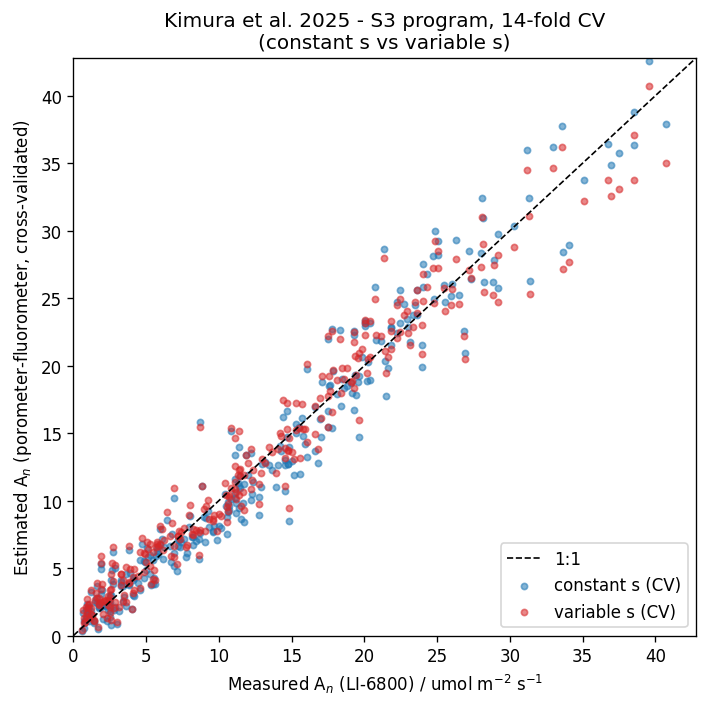

In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(6.0, 6.0), dpi=120)
lims = [0, max(cv["An_measured"].max(), cv["An_estimated_s_variable"].max()) * 1.05]
ax.plot(lims, lims, "k--", lw=1, label="1:1")
ax.scatter(cv["An_measured"], cv["An_estimated_s_constant"], s=14, alpha=0.55,
           color="#1f77b4", label="constant s (CV)")
ax.scatter(cv["An_measured"], cv["An_estimated_s_variable"], s=14, alpha=0.55,
           color="#d62728", label="variable s (CV)")
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel("Measured A$_n$ (LI-6800) / umol m$^{-2}$ s$^{-1}$")
ax.set_ylabel("Estimated A$_n$ (porometer-fluorometer, cross-validated)")
ax.set_title("Kimura et al. 2025 - S3 program, 14-fold CV\n(constant s vs variable s)")
ax.legend(loc="lower right")
fig.tight_layout()
plt.savefig("/content/c713/cv_estimated_vs_measured.png", dpi=120)
plt.show()

## Interpretation / 結果の解釈

- The author-provided program reproduces the paper's calibration on the published dataset: the all-species
  constant *s* matches 0.259, the variable-*s* sigmoid spans ≈ 0.246–0.286, and the cross-validated RMSE is
  ≈ 2.0 µmol m⁻² s⁻¹, matching the abstract. Small deviations from the printed paper values (if any) come
  from the stochastic differential-evolution search; the program fixes `set.seed(2)` for reproducibility.
- Both calibrated schemes sit ~38–41% below the often-used s = 0.42, the paper's central finding: with
  s = 0.42 the method would systematically overestimate A_n. The variable scheme performs slightly better
  under sunlight because s decreases with ΦPSII·PPFD.
- **This single run verifies the calibration/cross-validation computation on the published dataset; it does
  not re-measure anything in the field nor verify the LI-600 hardware method itself.**
- 日本語: 著者提供プログラムをそのまま実行した結果、定数 s = 0.259、可変 s ≈ 0.246–0.286、交差検証RMSE ≈ 2.0
  µmol m⁻² s⁻¹ が再現されました。s = 0.42 を用いた場合より約38%低い値で、日射下では s が ΦPSII·PPFD と共に
  減少することを確認できます。

## Validation record & references

- Executed on a fresh Colab **CPU** runtime (standard shape); measured timings are printed by the cells above.
- Sources: published article JATS via Europe PMC (PMC12415414, CC BY 4.0); supplementary bundle
  (`supplementaryFiles`) from Europe PMC REST; S3 R program (7,227 bytes) and S2 dataset (172,199 bytes)
  verified by size on extraction. Author code: Kimura et al. 2025, Supporting Information S3, retrieved 2026-10-26.
- Adaptation: single input-path line for headless execution (documented above). No other changes.
- References: Farquhar et al. 1980; Loreto et al. 2009; Yin et al. 2009; van der Putten et al. 2018;
  McClain & Sharkey 2020 — as cited by the paper.
- 論文・コード・データの 출처は上記の通りです。本ノートブックは単一データセット上の再現であり、
  論文の全結果(図・種別解析)の完全な検証ではありません。